# Лабораторная работа №2

Номер по списку: **3**, ПК: **3**, группа: **2**.

Варианты таблиц выбираются по кругу: (номер−1) % число строк + 1. Для ЛР3–4 N=ПК+группа; N не является номером по списку.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats, special
import pywt
plt.rcParams.update({'figure.figsize': (12,4), 'figure.dpi': 100,
                     'axes.grid': True, 'grid.alpha': .25})
number=3; pc=3; group=2
rng=np.random.default_rng(303)


## Формирование процесса с заданной КФ
Вариант 3: $R(\tau)=\cos(10\tau/l)e^{-(\tau/l)^2/2}$, $l_1=3$ мкс, $l_2=6$ мкс. Дополнительно исследуется экспоненциальная КФ.
БГШ $X\sim N(0,2^2)$ → БПФ → умножение на $H=\sqrt{\mathrm{DFT}(R)}$ → ОБПФ → Y.
По Винеру — Хинчину $S_Y=|H|^2S_X$. Нормировка $R(0)=1$ сохраняет дисперсию; линейная фильтрация сохраняет гауссовость.
СКО 2 принято по номеру группы, поскольку отдельного значения в ЛР2 нет. Усредняются 10 КФ и 20 СПМ. Фильтрация циклическая; длительность записи значительно больше l.
Для осциллирующей КФ СПМ имеет два гауссовских максимума на $\pm10/(2\pi l)$.

Экспоненциальная M= -0.04629817800783261 D= 4.00057448600361 теория D= 4
Вариант l₁ M= 7.860465750519907e-20 D= 3.893884371167244 теория D= 4
Вариант 2l₁ M= 4.824699667560495e-19 D= 3.973287782707897 теория D= 4


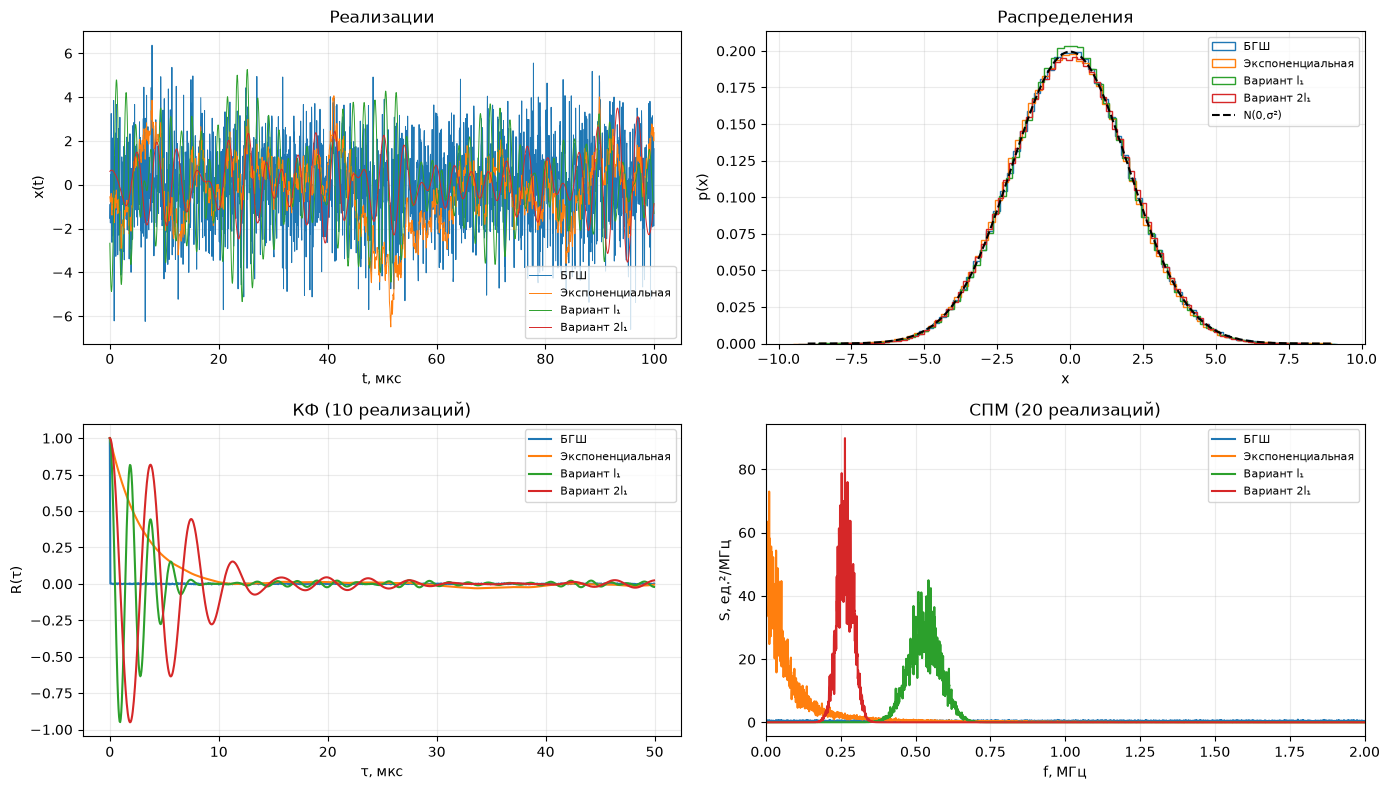

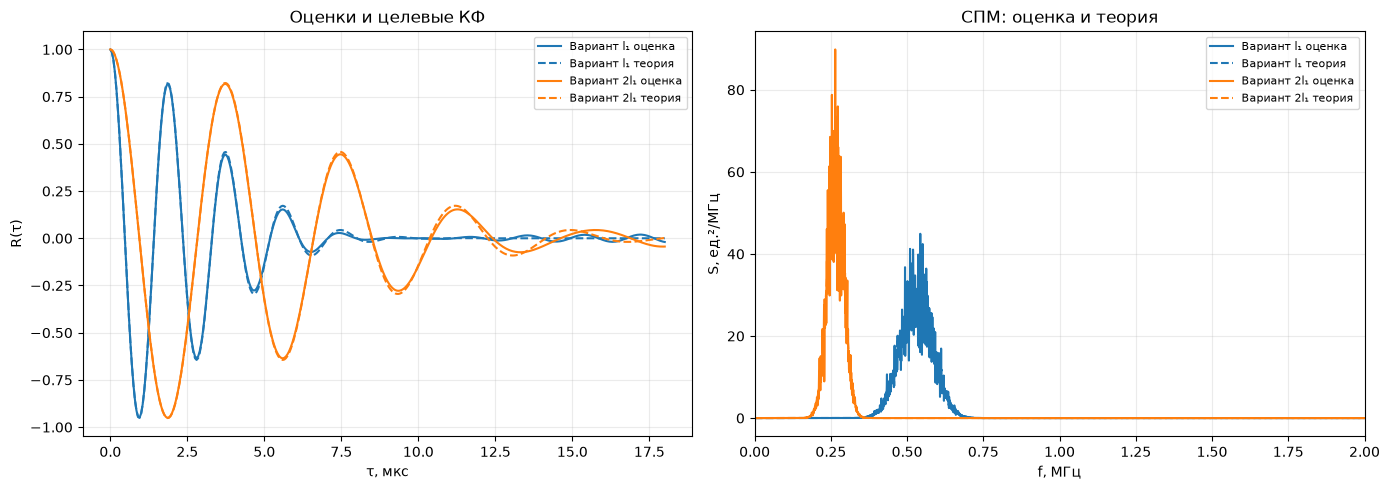

Интеграл СПМ / дисперсия: 3.893884371167245 3.893884371167244


In [2]:
dt=.05; count=32768; sigma=group; l1=pc
T=count*dt; t=np.arange(count)*dt; freq=np.fft.rfftfreq(count,dt)
tau=(np.arange(count)-count//2)*dt
x=rng.normal(0,sigma,(20,count))
def target(tau,l): return np.cos(10*tau/l)*np.exp(-.5*(tau/l)**2)
def acf(a):
    a=a-a.mean(axis=-1,keepdims=True)
    c=signal.correlate(a,a,mode='full',method='fft')[len(a)-1:]
    return c/(len(a)*np.var(a))
def psd(a):
    p=np.abs(np.fft.rfft(a,axis=-1))**2*dt/count
    p[:,1:-1]*=2
    return p.mean(axis=0)
def shaped(fun):
    s=np.fft.rfft(np.fft.ifftshift(fun(tau))).real
    assert s.min()>-1e-7, 'КФ не положительно определена на выбранной сетке'
    s=np.maximum(s,0)
    y=np.fft.irfft(np.fft.rfft(x,axis=-1)*np.sqrt(s),n=count,axis=-1)
    theory=s*sigma**2*dt; theory[1:-1]*=2
    return y,theory
results={'БГШ':(x,None,None)}
for label,fun in [('Экспоненциальная',lambda q:np.exp(-np.abs(q)/l1)),
                  ('Вариант l₁',lambda q:target(q,l1)),('Вариант 2l₁',lambda q:target(q,2*l1))]:
    y,s=shaped(fun); results[label]=(y,s,fun)
    print(label,'M=',y.mean(),'D=',y.var(),'теория D=',sigma**2)
fig,axs=plt.subplots(2,2,figsize=(14,8))
for label,(y,s,fun) in results.items():
    axs[0,0].plot(t[:2000],y[0,:2000],lw=.7,label=label)
    axs[0,1].hist(y.ravel(),bins=80,density=True,histtype='step',label=label)
    axs[1,0].plot(np.arange(1000)*dt,np.mean([acf(a)[:1000] for a in y[:10]],axis=0),label=label)
    axs[1,1].plot(freq,psd(y),label=label)
g=np.linspace(-9,9,300); axs[0,1].plot(g,stats.norm.pdf(g,scale=sigma),'k--',label='N(0,σ²)')
for ax,title,xlab,ylab in zip(axs.flat,['Реализации','Распределения','КФ (10 реализаций)','СПМ (20 реализаций)'],['t, мкс','x','τ, мкс','f, МГц'],['x(t)','p(x)','R(τ)','S, ед.²/МГц']):
    ax.set(title=title,xlabel=xlab,ylabel=ylab); ax.legend(fontsize=8)
axs[1,1].set_xlim(0,2); plt.tight_layout(); plt.show()
fig,axs=plt.subplots(1,2,figsize=(14,5))
for label in ['Вариант l₁','Вариант 2l₁']:
    y,s,fun=results[label]; lag=np.arange(count)*dt; limit=lag<=6*l1
    line,=axs[0].plot(lag[limit],np.mean([acf(a)[limit] for a in y[:10]],axis=0),label=label+' оценка')
    axs[0].plot(lag[limit],fun(lag[limit]),'--',color=line.get_color(),label=label+' теория')
    line,=axs[1].plot(freq,psd(y),label=label+' оценка')
    axs[1].plot(freq,s,'--',color=line.get_color(),label=label+' теория')
axs[0].set(xlabel='τ, мкс',ylabel='R(τ)',title='Оценки и целевые КФ'); axs[1].set(xlabel='f, МГц',ylabel='S, ед.²/МГц',xlim=(0,2),title='СПМ: оценка и теория')
for ax in axs: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Интеграл СПМ / дисперсия:',np.sum(psd(results['Вариант l₁'][0]))/(count*dt),results['Вариант l₁'][0].var())

## Выводы
Формирующий фильтр меняет корреляцию соседних отсчётов, сохраняя гауссовское распределение и ансамблевую дисперсию. При удвоении l КФ растягивается вдвое, а СПМ сжимается по частоте, сохраняя площадь. Усреднение уменьшает разброс оценок; смещённая оценка КФ содержит множитель $1-|\tau|/T$, поэтому при больших лагах отличается от цели.
Здесь оценивается центрированная нормированная ковариация. Для нулевого среднего она совпадает с нормированной корреляцией. При среднем m нецентрированная корреляция равна $B(\tau)=\sigma^2R(\tau)+m^2$, а ковариация — $K(\tau)=\sigma^2R(\tau)$.
Треугольная КФ имеет конечную область корреляции; осциллирующая КФ соответствует узкополосному шуму. Эти модели применяются к шумам после фильтра в радиоприёмнике.